# Evaluación de YOLO (clasificación) — 5 clases de residuos

Este notebook evalúa YOLO11-cls sobre el conjunto `data/raw/waste_classification/test`, usando el checkpoint nativo `.pt` generado por el entrenamiento.

Calcula las mismas métricas principales que los otros notebooks: **loss y accuracy global**, matriz de confusión, reporte precision/recall/F1, imágenes mal clasificadas, accuracy por clase y latencia referencial en el equipo actual.

**Modelo evaluado:** `models/YOLO/modelo_residuos_YOLO_v1.pt`.

> YOLO es un modelo PyTorch: su formato nativo es `.pt`, no `.keras`. El entrenamiento también exporta `models/YOLO/modelo_residuos_YOLO_v1.tflite` para despliegue; esta evaluación mide el checkpoint original `.pt`, no el runtime TFLite.

> Ejecuta primero `entrenamiento_YOLO.ipynb` y selecciona el kernel **Python 3.12 (EntrenamientoIA YOLO)**. Este notebook está guardado sin salidas hasta que lo ejecutes.

> 📁 Las rutas parten de `Path("../..")`, como en los otros notebooks de modelos.

### Importación de librerías

* **`numpy`:** operaciones con arreglos y probabilidades.
* **`matplotlib` y `seaborn`:** gráficas y matriz de confusión.
* **`ultralytics.YOLO` y `torch`:** carga, predicción y selección de GPU para el checkpoint `.pt` nativo.
* **`classification_report` y `confusion_matrix` (scikit-learn):** métricas detalladas por clase.
* **`pathlib.Path`:** manejo de rutas del proyecto.

In [1]:
import gc
from pathlib import Path

import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import torch
from sklearn.metrics import classification_report, confusion_matrix
from ultralytics import YOLO

### Configuración de rutas

* **`DATASET_DIR`:** `data/raw/waste_classification`.
* **`DATA_DIR`:** `.../test`, el set de **prueba**.
* **`MODEL_PATH`:** `models/YOLO/modelo_residuos_YOLO_v1.pt`.
* **`FIGURES_DIR`:** `reports/figures/`, donde se guardan las gráficas.
* **`DEVICE`:** GPU (`0`) si PyTorch la detecta; si no, CPU.

In [2]:
# --- 1. CONFIGURACIÓN DE RUTAS (Compatible Windows/Linux) ---
BASE_DIR = Path("../..")
DATASET_DIR = BASE_DIR / "data" / "raw" / "waste_classification"
DATA_DIR = DATASET_DIR / "test"
MODELS_DIR = BASE_DIR / "models" / "YOLO"
MODEL_PATH = MODELS_DIR / "modelo_residuos_YOLO_v1.pt"
FIGURES_DIR = BASE_DIR / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = 0 if torch.cuda.is_available() else "cpu"
IMG_SIZE = 224   # mismo tamaño que en el entrenamiento

### Verificación de archivos

Antes de hacer cualquier cálculo comprobamos que todo lo necesario existe, para obtener un error claro en vez de uno confuso más adelante.

1.  Si no existe la carpeta de prueba, se detiene con `FileNotFoundError` indicando la ruta buscada.
2.  Si no existe el modelo, se detiene pidiendo **ejecutar primero el notebook de entrenamiento**.

In [3]:
# Verificamos que existan
if not DATA_DIR.exists():
    raise FileNotFoundError(f"No se encontraron los datos en: {DATA_DIR}")
if not MODEL_PATH.exists():
    raise FileNotFoundError(f"No se encontró el modelo en: {MODEL_PATH}. ¡Ejecuta el entrenamiento primero!")

print("Rutas verificadas.")
print(f"Cargando modelo desde: {MODEL_PATH}")

Rutas verificadas.
Cargando modelo desde: ../../models/YOLO/modelo_residuos_YOLO_v1.pt


### Carga del modelo entrenado

`YOLO("archivo.pt")` reconstruye el modelo completo (backbone + cabeza de clasificación) con los pesos aprendidos. **No se vuelve a entrenar.**

Los nombres de las clases vienen **dentro del propio modelo** (`model.names`), en el mismo orden alfabético que en Keras: `aluminio, carton, otros, plastico, vidrio`.

In [4]:
# --- 2. CARGA DEL MODELO ---
model = YOLO(str(MODEL_PATH))
print("Modelo YOLO cargado exitosamente.")

class_names = [model.names[i] for i in range(len(model.names))]
name_to_idx = {n: i for i, n in enumerate(class_names)}
print(f"Clases detectadas: {len(class_names)} -> {class_names}")

Modelo YOLO cargado exitosamente.
Clases detectadas: 5 -> ['aluminio', 'carton', 'otros', 'plastico', 'vidrio']


### Preparación del set de prueba

Se arma la lista de imágenes de `test/` **en un orden fijo** (carpetas en orden alfabético y, dentro de cada una, archivos en orden alfabético) y se guardan sus etiquetas reales en `y_true`. Es el mismo orden que usaba `shuffle=False` en Keras: la posición *i* de las predicciones corresponde a la etiqueta real *i*.

Se comprueba además que las carpetas de `test/` coincidan exactamente con las clases del modelo.

In [5]:
# --- 3. PREPARACIÓN DE DATOS (Solo Prueba, sin Data Augmentation) ---
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

carpetas = sorted(p.name for p in DATA_DIR.iterdir() if p.is_dir())
assert set(carpetas) == set(class_names), (
    f"Las carpetas de test no coinciden con las clases del modelo:\n test={carpetas}\n modelo={class_names}"
)

filepaths, y_true = [], []
for clase in carpetas:
    for f in sorted((DATA_DIR / clase).rglob("*")):
        if f.suffix.lower() in IMG_EXT:
            filepaths.append(str(f))
            y_true.append(name_to_idx[clase])

y_true = np.array(y_true)
print(f"Set de prueba: {len(filepaths)} imágenes en {len(class_names)} clases.")

Set de prueba: 4535 imágenes en 5 clases.


### Evaluación global

Se predice sobre el conjunto de prueba por bloques pequeños para limitar el uso de RAM y VRAM. Se calculan **accuracy**, **cross-entropy** y el tiempo de inferencia, y se guardan las predicciones para las métricas detalladas.

* Las imágenes se procesan en bloques de 128 y lotes de 4; puedes reducir `BATCH_SIZE` a 1 si tu equipo vuelve a quedarse sin memoria.
* El orden de las rutas se conserva para que cada predicción coincida con su etiqueta real.
* La pérdida se calcula como *categorical crossentropy* a partir de la probabilidad asignada a la clase correcta.

> El entrenamiento usa `test/` como validación por época; los resultados de este mismo conjunto no constituyen una evaluación totalmente independiente.

In [6]:
print("Evaluando el modelo con los datos de prueba por bloques...")

y_pred = []
p_true = []          # probabilidad asignada a la clase correcta (para el loss)
tiempos_inf = []     # ms de inferencia por imagen

BATCH_SIZE = 4       # lote pequeño para reducir consumo de RAM y VRAM
CHUNK_SIZE = 128     # no enviar toda la lista de imágenes a una sola corrida

for inicio in range(0, len(filepaths), CHUNK_SIZE):
    bloque = filepaths[inicio:inicio + CHUNK_SIZE]
    resultados = model.predict(
        bloque,
        imgsz=IMG_SIZE,
        batch=BATCH_SIZE,
        stream=True,
        verbose=False,
        device=DEVICE,
    )

    for offset, resultado in enumerate(resultados):
        idx = inicio + offset
        probs = resultado.probs.data.cpu().numpy()
        y_pred.append(int(np.argmax(probs)))
        p_true.append(float(probs[y_true[idx]]))
        tiempos_inf.append(float(resultado.speed["inference"]))

    del resultados, bloque
    gc.collect()
    if DEVICE != "cpu":
        torch.cuda.empty_cache()

    procesadas = min(inicio + CHUNK_SIZE, len(filepaths))
    print(f"  Procesadas {procesadas}/{len(filepaths)} imágenes...")

y_pred = np.asarray(y_pred, dtype=np.int64)
p_true = np.clip(np.asarray(p_true, dtype=np.float32), 1e-7, 1.0)
tiempo_por_imagen = np.asarray(tiempos_inf, dtype=np.float32)

assert len(y_pred) == len(y_true), (
    f"Se obtuvieron {len(y_pred)} predicciones para {len(y_true)} etiquetas."
)

accuracy = float(np.mean(y_pred == y_true))
loss = float(np.mean(-np.log(p_true)))

print("\nResultados Finales:")
print(f"   Pérdida (Loss): {loss:.4f}")
print(f"   Precisión (Accuracy): {accuracy*100:.2f}%")

Evaluando el modelo con los datos de prueba por bloques...


/home/cachyisus/Proyectos/EntrenamientoIA/.venv-yolo/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


  Procesadas 128/4535 imágenes...
  Procesadas 256/4535 imágenes...
  Procesadas 384/4535 imágenes...
  Procesadas 512/4535 imágenes...
  Procesadas 640/4535 imágenes...
  Procesadas 768/4535 imágenes...
  Procesadas 896/4535 imágenes...
  Procesadas 1024/4535 imágenes...
  Procesadas 1152/4535 imágenes...
  Procesadas 1280/4535 imágenes...
  Procesadas 1408/4535 imágenes...
  Procesadas 1536/4535 imágenes...
  Procesadas 1664/4535 imágenes...
  Procesadas 1792/4535 imágenes...
  Procesadas 1920/4535 imágenes...
  Procesadas 2048/4535 imágenes...
  Procesadas 2176/4535 imágenes...
  Procesadas 2304/4535 imágenes...
  Procesadas 2432/4535 imágenes...
  Procesadas 2560/4535 imágenes...
  Procesadas 2688/4535 imágenes...
  Procesadas 2816/4535 imágenes...
  Procesadas 2944/4535 imágenes...
  Procesadas 3072/4535 imágenes...
  Procesadas 3200/4535 imágenes...
  Procesadas 3328/4535 imágenes...
  Procesadas 3456/4535 imágenes...
  Procesadas 3584/4535 imágenes...
  Procesadas 3712/4535 imág

### Matriz de confusión y reporte de clasificación

Las predicciones ya están calculadas (`y_pred`); aquí se comparan con las etiquetas reales (`y_true`).

**Matriz de confusión:**
* Cada **fila** es la clase real y cada **columna** la clase que predijo el modelo.
* La **diagonal** son los aciertos; todo lo que está fuera son errores.
* Se guarda en `reports/figures/matriz_confusion_YOLO.png`.

**Reporte de clasificación (por clase):**
* **Precision:** de todo lo que el modelo dijo que era de esa clase, ¿cuánto lo era realmente?
* **Recall:** de todo lo que realmente era de esa clase, ¿cuánto encontró el modelo?
* **F1-score:** promedio armónico de precision y recall.
* **Support:** cuántas imágenes reales hay de esa clase.
* **Macro avg** promedia las clases por igual; **weighted avg** pondera por la cantidad de imágenes de cada clase.

Generando reporte detallado...


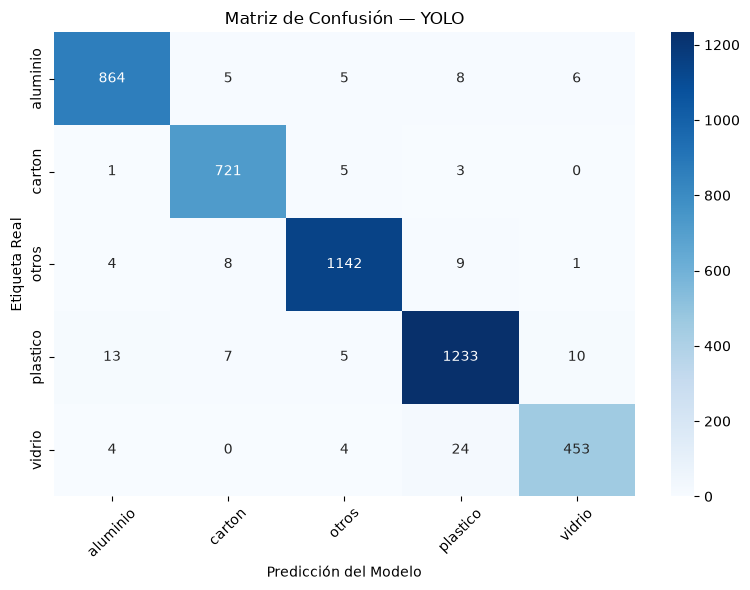


Reporte de Clasificación Detallado:
              precision    recall  f1-score   support

    aluminio       0.98      0.97      0.97       888
      carton       0.97      0.99      0.98       730
       otros       0.98      0.98      0.98      1164
    plastico       0.97      0.97      0.97      1268
      vidrio       0.96      0.93      0.95       485

    accuracy                           0.97      4535
   macro avg       0.97      0.97      0.97      4535
weighted avg       0.97      0.97      0.97      4535



In [7]:
print("Generando reporte detallado...")

# --- MATRIZ DE CONFUSIÓN ---
# Cada fila representa la clase real, cada columna la clase predicha.
# Los valores en la diagonal son aciertos; fuera de ella, errores.
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names)
plt.title('Matriz de Confusión — YOLO')
plt.ylabel('Etiqueta Real')
plt.xlabel('Predicción del Modelo')
plt.xticks(rotation=45)
plt.tight_layout()
save_path = FIGURES_DIR / "matriz_confusion_YOLO.png"
plt.savefig(save_path, dpi=300)
plt.show()

# --- REPORTE DE CLASIFICACIÓN ---
print("\nReporte de Clasificación Detallado:")
print(classification_report(y_true, y_pred, target_names=class_names))

### Matriz de confusión en texto

Imprime la misma matriz como arreglo de NumPy. Es útil para copiar los números exactos al reporte y mantiene el mismo formato de salida que el notebook de EfficientNetB0.

In [8]:
print(cm)

[[ 864    5    5    8    6]
 [   1  721    5    3    0]
 [   4    8 1142    9    1]
 [  13    7    5 1233   10]
 [   4    0    4   24  453]]


### Conteo de errores

`np.where(y_pred != y_true)` devuelve los índices de las imágenes mal clasificadas. Con ellos calculamos cuántos errores hubo y volvemos a obtener la accuracy de forma manual (debe coincidir con la de la evaluación global).

Los índices quedan guardados en `errors` para inspeccionarlos visualmente en la celda siguiente.

In [9]:
# Buscamos dónde la predicción no coincide con la realidad
errors = np.where(y_pred != y_true)[0]

print(f"\nTotal de errores encontrados: {len(errors)} de {len(y_true)} imágenes reales.")
print(f"   Precisión Global (Accuracy): {1 - len(errors)/len(y_true):.2%}")


Total de errores encontrados: 122 de 4535 imágenes reales.
   Precisión Global (Accuracy): 97.31%


### Inspección visual de errores

Los números dicen *cuánto* se equivoca el modelo; ver las imágenes ayuda a entender *por qué*.

1.  Se toman las rutas de las imágenes en el mismo orden que las predicciones.
2.  Se muestran hasta **5 errores**, cada uno con su etiqueta real y la predicción del modelo (título en rojo).
3.  Si no hubiera errores, se indica con un mensaje.

> ℹ️ Se muestran siempre los **primeros** 5 errores del set (en orden de carpeta), igual que en el notebook de EfficientNetB0, lo que permite comparar los mismos casos entre modelos.


Mostrando 5 ejemplos de clasificaciones incorrectas:


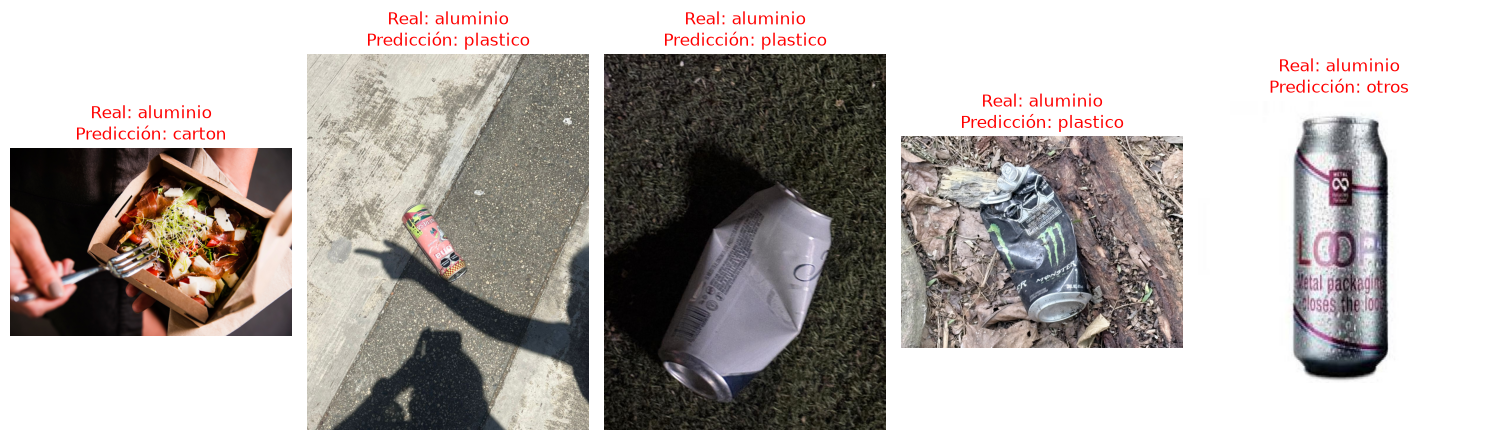

In [10]:
# Cuántos errores queremos ver en pantalla (máximo 5 para no saturar)
num_errores_a_mostrar = min(5, len(errors))

if num_errores_a_mostrar > 0:
    print(f"\nMostrando {num_errores_a_mostrar} ejemplos de clasificaciones incorrectas:")
    plt.figure(figsize=(15, 5))

    for i in range(num_errores_a_mostrar):
        # Índice del error en el dataset
        idx = errors[i]

        # Etiquetas correspondientes
        etiqueta_real = class_names[y_true[idx]]
        etiqueta_predicha = class_names[y_pred[idx]]

        # Cargar y mostrar la imagen
        img = mpimg.imread(filepaths[idx])
        plt.subplot(1, num_errores_a_mostrar, i + 1)
        plt.imshow(img)

        # El título mostrará en rojo la equivocación
        plt.title(f"Real: {etiqueta_real}\nPredicción: {etiqueta_predicha}", color='red')
        plt.axis('off')

    plt.tight_layout()
    plt.show()
else:
    print("¡Excelente trabajo! El modelo no cometió ningún error en el set de pruebas.")

### Accuracy por clase

Para cada clase se filtran solo las imágenes que realmente pertenecen a ella (`mask = y_true == i`) y se calcula qué porcentaje acertó el modelo. Este valor es igual al **recall** de esa clase en el reporte de clasificación.

Permite identificar qué categorías le cuestan más al modelo y es uno de los datos usados en el reporte comparativo entre modelos.

In [11]:
# Accuracy por clase — permite identificar qué categorías le cuestan más al modelo.
print("\nAccuracy por clase:")
print("-" * 35)
for i, class_name in enumerate(class_names):
    mask = y_true == i
    class_acc = np.mean(y_pred[mask] == y_true[mask])
    print(f"  {class_name:<12}: {class_acc*100:.2f}%")


Accuracy por clase:
-----------------------------------
  aluminio    : 97.30%
  carton      : 98.77%
  otros       : 98.11%
  plastico    : 97.24%
  vidrio      : 93.40%


### Extra: tiempo de inferencia por imagen

Dato adicional para el reporte comparativo, importante porque el objetivo final es la Raspberry Pi. Se calcula con los tiempos que Ultralytics midió durante la evaluación (solo la **inferencia del modelo**, sin lectura de disco ni preprocesamiento).

> ⚠️ Estos tiempos son de **esta computadora** (GPU o CPU según `DEVICE`) y con el modelo `.pt`. **No son los de la Raspberry Pi.** Sirven para comparar modelos entre sí en el mismo equipo, no como medida de rendimiento final. Se descartan las primeras 10 imágenes porque incluyen el calentamiento del modelo.

In [12]:
t = np.array(tiempos_inf[10:])
print(f"Dispositivo: {'GPU' if DEVICE == 0 else 'CPU'}")
print(f"Tiempo de inferencia por imagen (ms) -> media: {t.mean():.2f} | mediana: {np.median(t):.2f} | p95: {np.percentile(t, 95):.2f}")

Dispositivo: GPU
Tiempo de inferencia por imagen (ms) -> media: 0.89 | mediana: 0.62 | p95: 2.48
